[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# Cómo entrenar Clasificación YOLOv8 en un conjunto de datos personalizado

---

[![Roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset)
[![YouTube](https://badges.aleen42.com/src/youtube.svg)](https://youtu.be/wuZtUMEiKWY)
[![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

Ultralytics YOLOv8 es la última versión del modelo de detección de objetos y segmentación de imágenes YOLO (You Only Look Once) desarrollado por Ultralytics. El modelo YOLOv8 está diseñado para ser rápido, preciso y fácil de usar, lo que lo convierte en una excelente opción para una amplia gama de tareas de detección de objetos y segmentación de imágenes. Puede entrenarse en grandes conjuntos de datos y es capaz de ejecutarse en una variedad de plataformas de hardware, desde CPU hasta GPU.

## ⚠️ Nota histórica sobre la clasificación en YOLOv8

> **Descargo original (18/01/2023):** en esa fecha el modo `classify` estaba poco maduro —el modelo
> preentrenado devolvía *ids* de clase en lugar de nombres, faltaban métricas de entrenamiento y las
> salidas por CLI/SDK eran poco utilizables.

**Estado actual:** ese descargo ya no aplica tal cual. La versión que instala este notebook
(Ultralytics ≥ 8.3) tiene `classify` estable y guarda métricas y predicciones en `runs/classify/`.
Se conserva la nota —actualizada— porque explica los dos hábitos que sí siguen vigentes:

1. En clasificación, la salida es un **vector de probabilidades**: hay que mapearlo a nombres con
   `model.names` (ver la celda del SDK más abajo).
2. Conviene revisar `results.csv` y las imágenes anotadas para interpretar el resultado; el CLI no
   imprime un informe de texto.

## Publicación de blog adjunta

Le recomendamos que siga este cuaderno mientras lee la publicación del blog sobre cómo entrenar la Clasificación YOLOv8, al mismo tiempo.

## Consejo profesional: usar aceleración de GPU

Si está ejecutando este cuaderno en Google Colab, navegue hasta `Editar` -> `Configuración del cuaderno` -> `Acelerador de hardware`, configúrelo en `GPU` y luego haga clic en `Guardar`. Esto asegurará que su cuaderno use una GPU, lo que acelerará significativamente los tiempos de entrenamiento del modelo.

## Pasos en este Tutorial

En este tutorial, cubriremos:

- Antes de empezar
- Instalar YOLOv8
- Conceptos básicos de CLI
- Inferencia con Modelo COCO Preentrenado
- Roboflow Universe
- Preparación de un conjunto de datos personalizado
- Entrenamiento personalizado
- Validar modelo personalizado
- Inferencia con modelo personalizado

**¡Comencemos!**

---

> 📘 **Versión corregida — 16/11/2026.** Copia de trabajo con las correcciones documentadas en
> `ERRORES_ENCONTRADOS.md` (proyecto `Clase_3_revision`). En el código, cada cambio está marcado
> con `# [CORREGIDO]`. El archivo original no se modificó.

**Grupo:** `____` · **Integrantes:** `____, ____, ____, ____`

> 🔧 **Actualización 18/11/2026 — celdas autocontenidas y vista de la imagen (V8-09, V8-10).**
> Ya no aparecen `NameError: YOLO`, `NameError: HOME` ni `ModuleNotFoundError: ultralytics` al
> ejecutar una celda suelta: la celda **🔧 Entorno** (después de `HOME = os.getcwd()`) instala e
> importa lo necesario. La vista de la imagen anotada busca el archivo más reciente en
> `runs/classify/predict*` (sirve con `predict2`, `predict3`… y con `.jpg`, `.jpeg` o `.png`).
> Las celdas de entrenamiento/validación siguen dependiendo del dataset y del modelo entrenado: ésas
> van en orden.

## Antes de empezar

Asegurémonos de que tenemos acceso a la GPU. Podemos usar el comando `nvidia-smi` para hacer eso. En caso de cualquier problema, navegue hasta `Editar` -> `Configuración del cuaderno` -> `Acelerador de hardware`, configúrelo en `GPU` y luego haga clic en `Guardar`.

In [1]:
# Si este comando falla, no hay GPU: Editá Configuración del cuaderno > Acelerador > GPU
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


### 🔧 Celda de entorno (ejecutala si reiniciaste el runtime)

Con esta celda ya no hace falta correr el notebook de principio a fin para probar una parte:
deja instalado `ultralytics`, importado `YOLO` y definido `HOME`. Las celdas de entrenamiento,
validación y predicción con el modelo propio sí necesitan el dataset y el modelo entrenado.

In [3]:
# ─── ENTORNO: primero esta celda (y cada vez que reinicies el runtime) ───
# [CORREGIDO] V8-09: instala ultralytics si falta, importa YOLO y fija HOME.
# Evita los errores clásicos al ejecutar celdas sueltas:
#   NameError: name 'YOLO' is not defined
#   NameError: name 'HOME' is not defined
#   ModuleNotFoundError: No module named 'ultralytics'

import os, sys

HOME = globals().get('HOME') or os.getcwd()
print('HOME:', HOME)

try:
    import ultralytics
except ModuleNotFoundError:
    print('ultralytics no está instalado: instalando (equivale a %pip install)...')
    import subprocess
    subprocess.check_call(
        [sys.executable, '-m', 'pip', 'install', '-q', '-U', 'ultralytics>=8.3']
    )
    import ultralytics

from ultralytics import YOLO
from IPython.display import display, Image

print(f'ultralytics {ultralytics.__version__} · YOLO importado · HOME listo')

HOME: /content
ultralytics no está instalado: instalando (equivale a %pip install)...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216 · YOLO importado · HOME listo


## Instalar YOLOv8

Nos esforzamos para que nuestros cuadernos YOLOv8 funcionen con la última versión de la biblioteca. Las últimas pruebas se realizaron el **06.10.2024** con la versión **YOLOv8.3.7**.

Si nota que nuestro cuaderno se comporta incorrectamente, especialmente si experimenta errores que le impiden seguir el tutorial, ¡no lo dude! Háganoslo saber y abra un [problema](https://github.com/roboflow/notebooks/issues) en el repositorio de Cuadernos de Roboflow.

YOLOv8 se puede instalar de dos maneras: desde la fuente y a través de pip. Esto se debe a que es la primera iteración de YOLO en tener un paquete oficial.

In [4]:
# Método de instalación Pip (recomendado)

# [CORREGIDO] no se fija 8.2.103: es anterior a numpy 2.x y en un Colab actual
# puede fallar (AttributeError: module 'numpy' has no attribute 'float_',
# o conflictos de torch/torchvision). Se instala la última versión estable.
%pip install -q -U "ultralytics>=8.3"
# evitar que ultralytics rastree tu actividad
!yolo settings sync=False
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 1.4/225.8 GB disk)


In [5]:
# Método de clonación de Git (para desarrollo)

# %cd {HOME}
# !git clone github.com/ultralytics/ultralytics
# %cd {HOME}/ultralytics
# !pip install -e .

# from IPython import display
# display.clear_output()

# import ultralytics
# ultralytics.checks()

In [6]:
from ultralytics import YOLO

from IPython.display import display, Image

## Conceptos básicos de CLI

Si desea entrenar, validar o ejecutar inferencias en modelos y no necesita realizar modificaciones en el código, usar la interfaz de línea de comandos de YOLO es la forma más fácil de comenzar. Lea más sobre CLI en los [Documentos de Ultralytics YOLO](https://docs.ultralytics.com/usage/cli/).

```
yolo task=detect    mode=train    model=yolov8n.yaml      args...
          classify       predict        yolov8n-cls.yaml  args...
          segment        val            yolov8n-seg.yaml  args...
                         export         yolov8n.pt        format=onnx  args...
```

## Inferencia con Modelo COCO Preentrenado

### 💻 CLI

`yolo mode=predict` ejecuta la inferencia de YOLOv8 en una variedad de fuentes, descargando modelos automáticamente de la última versión de YOLOv8 y guardando los resultados en `runs/predict`.

In [7]:
import os, shutil

# [CORREGIDO] autocontenida: no depende de la celda de HOME ni del orden de ejecución
HOME = globals().get('HOME') or os.getcwd()
if shutil.which('yolo') is None:
    raise RuntimeError('El comando `yolo` no está disponible: ejecutá la celda 🔧 Entorno primero.')
%cd {HOME}

# [CORREGIDO] `conf` es un umbral de detección: no aplica a clasificación
!yolo task=classify mode=predict model=yolov8n-cls.pt imgsz=224 source='https://media.roboflow.com/notebooks/examples/dog.jpeg'

/content
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLOv8n-cls summary (fused): 30 layers, 2,715,880 parameters, 0 gradients, 3.3 GFLOPs

image 1/1 /content/dog.jpeg: 224x224 seat_belt 0.28, Walker_hound 0.24, beagle 0.15, basset 0.11, Labrador_retriever 0.04, 113.9ms
Speed: 27.9ms preprocess, 113.9ms inference, 0.2ms postprocess per image at shape (1, 3, 224, 224)
Results saved to /content/runs/classify/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


/content
Mostrando: runs/classify/predict/dog.jpg


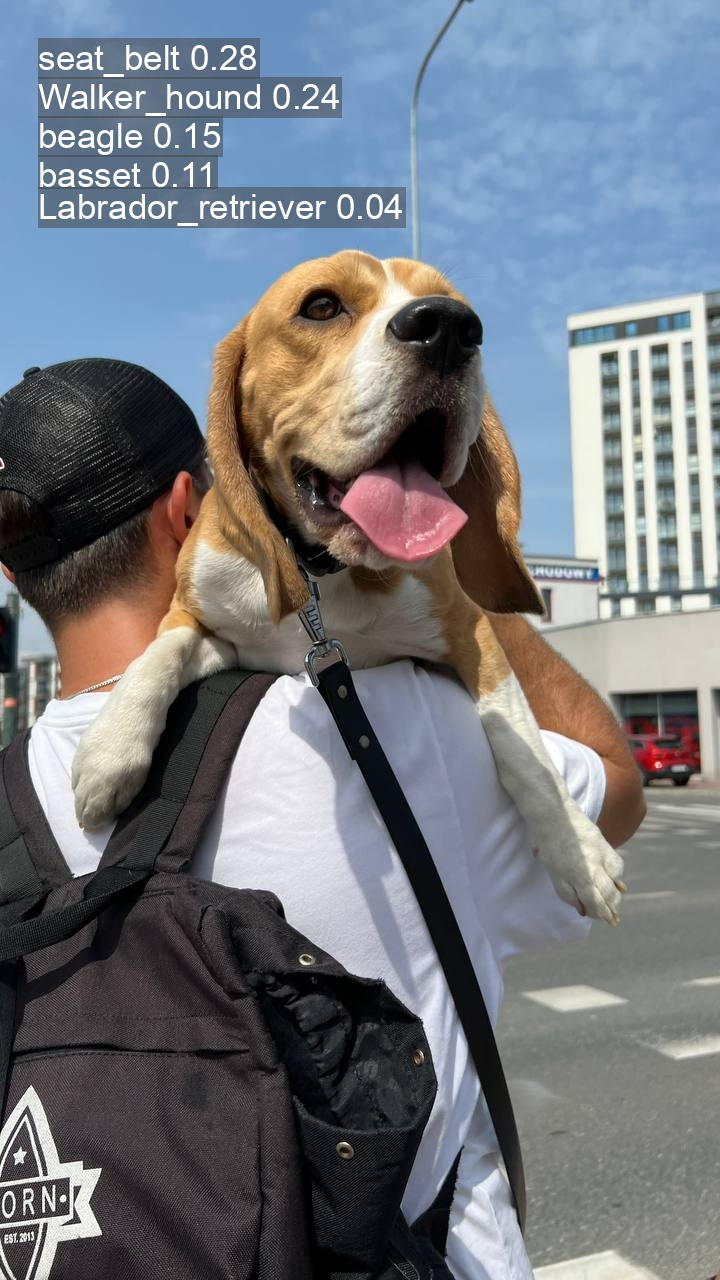

In [8]:
import glob
import os
from IPython.display import Image   # [CORREGIDO] autocontenida

HOME = globals().get('HOME') or os.getcwd()
%cd {HOME}

# [CORREGIDO] la ruta no es fija: cada reejecución del CLI crea predict2, predict3...
# y Ultralytics puede guardar la anotada como .jpg aunque la fuente sea .jpeg.
_candidatas = sorted(
    glob.glob('runs/classify/predict*/*.jpg')
    + glob.glob('runs/classify/predict*/*.jpeg')
    + glob.glob('runs/classify/predict*/*.png'),
    key=os.path.getmtime,
    reverse=True,
)
if not _candidatas:
    raise FileNotFoundError(
        'No hay imágenes anotadas en runs/classify/predict*/. '
        'Ejecutá antes la celda de CLI (task=classify mode=predict).'
    )

_anotada = _candidatas[0]
print('Mostrando:', _anotada)
Image(filename=_anotada, height=600)

### 🐍 SDK de Python

La forma más sencilla de utilizar simplemente YOLOv8 directamente en un entorno de Python.

In [9]:
import os

try:
    from ultralytics import YOLO   # [CORREGIDO] autocontenida
except ModuleNotFoundError as _e:
    raise ModuleNotFoundError(
        'Falta ultralytics: ejecutá la celda 🔧 Entorno, o '
        '%pip install -U "ultralytics>=8.3" y reiniciá el runtime.'
    ) from _e

# [CORREGIDO] sin HOME ni ruta absoluta: si el .pt no está, Ultralytics lo descarga solo
model = YOLO('yolov8n-cls.pt')
results = model.predict(source='https://media.roboflow.com/notebooks/examples/dog.jpeg', imgsz=224)

# [CORREGIDO] el SDK devuelve probabilidades: para obtener el nombre de la clase
# hay que mapear el índice con model.names (era la limitación del descargo de 2023)
probs = results[0].probs
print('Clase predicha:', model.names[probs.top1], f'({float(probs.top1conf):.1%})')
print('Top-5:', [(model.names[i], round(float(c), 3))
                 for i, c in zip(probs.top5, probs.top5conf)])


Found https://media.roboflow.com/notebooks/examples/dog.jpeg locally at dog.jpeg
image 1/1 /content/dog.jpeg: 224x224 seat_belt 0.28, Walker_hound 0.24, beagle 0.15, basset 0.11, Labrador_retriever 0.04, 15.2ms
Speed: 8.9ms preprocess, 15.2ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)
Clase predicha: seat_belt (28.2%)
Top-5: [('seat_belt', 0.282), ('Walker_hound', 0.242), ('beagle', 0.151), ('basset', 0.109), ('Labrador_retriever', 0.036)]


## Roboflow Universe

¿Necesita datos para su proyecto? Antes de perder tiempo anotando, consulte Roboflow Universe, un repositorio de más de 110,000 conjuntos de datos de código abierto que puede usar en sus proyectos. Encontrará conjuntos de datos que contienen de todo, desde grietas anotadas en hormigón hasta imágenes de plantas con anotaciones de enfermedades.


[![Roboflow Universe](https://media.roboflow.com/notebooks/template/uni-banner-frame.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672878480290)](https://universe.roboflow.com/)



## Preparación de un conjunto de datos personalizado

Construir un conjunto de datos personalizado puede ser un proceso doloroso. Puede llevar docenas o incluso cientos de horas recopilar imágenes, etiquetarlas y exportarlas en el formato adecuado. Afortunadamente, Roboflow hace que este proceso sea lo más sencillo y rápido posible. ¡Déjame mostrarte cómo!

### Paso 1: Creación del proyecto

Antes de comenzar, debe crear una [cuenta](https://app.roboflow.com/login) de Roboflow. Una vez que lo haga, puede crear un nuevo proyecto en el [panel](https://app.roboflow.com/) de Roboflow. Tenga en cuenta elegir el tipo de proyecto correcto. En nuestro caso, **Clasificación** (no Detección de Objetos).

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/creating-project.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672929799852"
  >
</div>

### Paso 2: Subir imágenes

A continuación, agregue los datos a su proyecto recién creado. Puede hacerlo a través de API o mediante nuestra [interfaz web](https://docs.roboflow.com/adding-data/object-detection).

Si arrastra y suelta un directorio con un conjunto de datos en un formato compatible, el panel de Roboflow leerá automáticamente las imágenes y las anotaciones juntas.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/uploading-images.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672929808290"
  >
</div>

### Paso 3: Etiquetado

Si solo tiene imágenes, puede etiquetarlas en [Roboflow Annotate](https://docs.roboflow.com/annotate).

<div align="center">
  <img
    width="640"
    src="https://user-images.githubusercontent.com/26109316/210901980-04861efd-dfc0-4a01-9373-13a36b5e1df4.gif"
  >
</div>

### Paso 4: Generar nueva versión del conjunto de datos

Ahora que tenemos agregadas nuestras imágenes y anotaciones, podemos generar una Versión del Conjunto de Datos. Al generar una Versión, puede optar por agregar preprocesamiento y aumentos. Este paso es completamente opcional, sin embargo, puede permitirle mejorar significativamente la robustez de su modelo.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/generate-new-version.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1673003597834"
  >
</div>

### Paso 5: Exportar el conjunto de datos

Una vez generada la versión del conjunto de datos, tenemos un conjunto de datos alojado que podemos cargar directamente en nuestro cuaderno para facilitar el entrenamiento. Haga clic en `Export` y seleccione el formato de conjunto de datos `Folder Structure`.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/export.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672943313709"
  >
</div>



In [10]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow --quiet

import roboflow

roboflow.login()

rf = roboflow.Roboflow()

project = rf.workspace("model-examples").project("banana-ripeness-classification-cdvrn")
dataset = project.version(1).download("folder")

/content/datasets
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
visit https://app.roboflow.com/auth-cli to get your authentication token.


HTTPError: 404 Client Error: Not Found for url: https://app.roboflow.com/query/cliAuthToken/

In [ ]:
# [CORREGIDO] idempotente: al reejecutar ya no falla si val/ existe
import os, shutil

_origen, _destino = f"{dataset.location}/valid", f"{dataset.location}/val"
if os.path.isdir(_origen) and not os.path.isdir(_destino):
    shutil.move(_origen, _destino)
print('val/ listo:', os.path.isdir(_destino))

## Entrenamiento personalizado

In [ ]:
%cd {HOME}

!yolo task=classify mode=train model=yolov8n-cls.pt data={dataset.location} epochs=25 imgsz=128

In [ ]:
!ls -la {HOME}/runs/classify/train/

In [ ]:
!cat {HOME}/runs/classify/train/results.csv | head -10

## Validar modelo personalizado

In [ ]:
%cd {HOME}

# [CORREGIDO] imgsz=128 igual que en el entrenamiento: validar a 224 penaliza la métrica
!yolo task=classify mode=val model={HOME}/runs/classify/train/weights/best.pt data={dataset.location} imgsz=128

## Inferencia con modelo personalizado

In [ ]:
%cd {HOME}
# [CORREGIDO] sin `conf` (no aplica) y con el imgsz del entrenamiento
!yolo task=classify mode=predict model={HOME}/runs/classify/train/weights/best.pt imgsz=128 source={dataset.location}/test/overripe